# Gradient boosting (R3)

*Ahmed. Uses the clean table and folds from `02_data-analysis`.*

This is our gradient boosting baseline for both tasks: predicting the maths score (regression) and flagging students below Level 2 (classification). We start with gradient boosting because it copes with the blanks in the questionnaire indices by itself and can follow links that are not straight lines, which the EDA found. We use scikit-learn's `HistGradientBoostingClassifier` and `HistGradientBoostingRegressor` on the 17 predictors, tune two settings on PV1, check that the 100-tree cap is high enough, then run all 10 plausible values on the 5 school folds and combine them with Rubin's rules. Then we split the same test predictions by system, and in section 7 we look inside the model: where it goes wrong, whether more data would help, which cut-off to use, which predictors it relies on and what shape their links have. Section 7 is there so we can explain the scores in the report, not just quote them.

| Reads | Writes |
|---|---|
| `../data/clean/pisa6_clean.parquet` | `outputs/ahmed_hgb_params.json` |
| `../data/clean/columns.json` | `outputs/ahmed_hgb_results.csv` |
| `../data/clean/folds.csv` | `outputs/ahmed_hgb_by_system.csv` |
| | `outputs/ahmed_hgb_cutoffs.csv` |
| | `outputs/ahmed_hgb_importance.csv` |
| | `outputs/figures/ahmed_hgb_by_system.png` |
| | `outputs/figures/ahmed_hgb_curves.png` |
| | `outputs/figures/ahmed_hgb_learning_curve.png` |
| | `outputs/figures/ahmed_hgb_importance.png` |
| | `outputs/figures/ahmed_hgb_partial_dependence.png` |

# 1) Setup and data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, recall_score,
                             precision_score, root_mean_squared_error, mean_absolute_error, r2_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from scipy.stats import kendalltau
from itertools import combinations

DATA = Path("../data")
OUT = Path("outputs")
FIGS = OUT / "figures"
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "clean/folds.csv")
df["fold"] = df["CNTSCHID"].map(folds.set_index("CNTSCHID")["fold"])
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
PVS = range(1, 11)
SYSTEMS = ["ARE", "SAU", "QAT", "JOR", "MAR", "PSE"]
w = df["SENWT"] / df["SENWT"].mean()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# no reading or science scores, no plausible values among the features
assert not any(c.startswith("PV") or "READ" in c or "SCIE" in c for c in FEATURES)
X = df[FEATURES]
print(X.shape, "| blanks left in:", int(X.isna().sum().sum()))
print("share below Level 2 (PV1, SENWT):", round(np.average(df["BELOW_L2_PV1"], weights=w), 3))

(61775, 17) | blanks left in: 124267
share below Level 2 (PV1, SENWT): 0.7


Gradient boosting handles blanks itself (it learns which side of each split they go to), so we pass the 17 raw predictors with NaN left in. No imputer, no scaler, and no `_missing` flags, since the trees already see where the blanks are.

# 1.1) The loop
One function runs a model on the chosen plausible values and the 5 school folds. It returns the fold scores, the test predictions and the fitted models, so the per-system results in section 6 and most of section 7 reuse them with no refit. Fitting and predicting sit in two small functions of their own because the learning curve in 7.2 needs them on other rows. Training uses the normalised `SENWT` weights, and for classification we also multiply by balanced class weights so the 70% below Level 2 doesn't swamp the model. All metrics use `SENWT` on the test rows.

In [2]:
def score(task, y, p, sw):
    if task == "classification":
        return {"roc_auc": roc_auc_score(y, p, sample_weight=sw),
                "pr_auc": average_precision_score(y, p, sample_weight=sw),
                "balanced_acc": balanced_accuracy_score(y, p > 0.5, sample_weight=sw),
                "recall_below": recall_score(y, p > 0.5, pos_label=1, sample_weight=sw),
                "recall_above": recall_score(y, p > 0.5, pos_label=0, sample_weight=sw)}
    return {"rmse": root_mean_squared_error(y, p, sample_weight=sw),
            "mae": mean_absolute_error(y, p, sample_weight=sw),
            "r2": r2_score(y, p, sample_weight=sw)}


def target(task, pv):
    return df[f"BELOW_L2_PV{pv}"] if task == "classification" else df[f"PV{pv}MATH"]


def fit(task, params, rows, y):
    if task == "classification":
        model = HistGradientBoostingClassifier(**params, random_state=0)
        return model.fit(X[rows], y[rows], sample_weight=w[rows] * compute_sample_weight("balanced", y[rows]))
    model = HistGradientBoostingRegressor(**params, random_state=0)
    return model.fit(X[rows], y[rows], sample_weight=w[rows])


def predict(task, model, rows):
    return model.predict_proba(X[rows])[:, 1] if task == "classification" else model.predict(X[rows])


def run(task, params, pvs):
    rows, preds, models = [], {}, {}
    for pv in pvs:
        y = target(task, pv)
        pred = pd.Series(np.nan, index=df.index)
        for k in range(5):
            train, test = df["fold"] != k, df["fold"] == k
            model = fit(task, params, train, y)
            pred[test] = predict(task, model, test)
            models[(pv, k)] = model
            rows.append({"pv": pv, "fold": k, "trees": model.n_iter_, **score(task, y[test], pred[test], w[test])})
        preds[pv] = pred
    return pd.DataFrame(rows), preds, models


def rubin(res):
    # trees is a count from run, not a metric
    res = res.drop(columns=["fold", "trees"], errors="ignore")
    per_pv = res.groupby("pv").mean()
    within = res.groupby("pv").var().mean() / 5
    between = per_pv.var()
    return pd.DataFrame({"score": per_pv.mean(), "se": np.sqrt(within + 1.1 * between)})

`rubin` is the combining step from `NEXT_STEPS.md`: the score is the mean over plausible values of the fold mean, and the standard error adds the fold-to-fold noise to the PV-to-PV noise.

# 2) Tuning on PV1
A small grid: two learning rates and three tree sizes (`max_leaf_nodes`), 6 settings per task, scored on PV1 with the same 5 folds. We pick by ROC-AUC for classification and RMSE for regression. With this many rows scikit-learn turns on early stopping by itself (10% of the training rows held back), so it can stop before the default cap of `max_iter=100` trees. Whether that cap is high enough is checked in 2.1.

In [3]:
GRID = [{"learning_rate": lr, "max_leaf_nodes": leaves} for lr in [0.05, 0.1] for leaves in [15, 31, 63]]

tuning = []
for params in GRID:
    clf_res, _, _ = run("classification", params, [1])
    reg_res, _, _ = run("regression", params, [1])
    tuning.append({**params, "roc_auc": clf_res["roc_auc"].mean(), "rmse": reg_res["rmse"].mean()})
tuning = pd.DataFrame(tuning)
tuning.round(4)

,learning_rate,max_leaf_nodes,roc_auc,rmse
0,0.05,15,0.8172,61.3015
1,0.05,31,0.8179,61.0444
2,0.05,63,0.8167,60.9491
3,0.10,15,0.8178,61.0700
4,0.10,31,0.8167,60.9568
5,0.10,63,0.8147,61.1015


In [4]:
best = {"classification": GRID[tuning["roc_auc"].idxmax()],
        "regression": GRID[tuning["rmse"].idxmin()]}
(OUT / "ahmed_hgb_params.json").write_text(json.dumps(best, indent=2), encoding="utf-8")
best

{'classification': {'learning_rate': 0.05, 'max_leaf_nodes': 31},
 'regression': {'learning_rate': 0.05, 'max_leaf_nodes': 63}}

> **Note:** the six settings land close together: ROC-AUC goes from 0.815 to 0.818 and RMSE from 60.95 to 61.30 points, so the choice matters little. The winners above are saved to `outputs/ahmed_hgb_params.json`, and the ablations notebook reads them from there.

# 2.1) Is 100 trees enough?
If early stopping never triggers, the model stops at the cap and not because the held-back rows stopped improving. So we rerun each winner on PV1 with `max_iter` at 100 and at 1000, and look at how many trees it actually used (`n_iter_`, mean over the 5 folds). The score is ROC-AUC for classification and RMSE for regression.

In [5]:
check = []
for task, metric in [("classification", "roc_auc"), ("regression", "rmse")]:
    for max_iter in [100, 1000]:
        res, _, _ = run(task, {**best[task], "max_iter": max_iter}, [1])
        check.append({"task": task, "max_iter": max_iter, "trees": res["trees"].mean(), "score": res[metric].mean()})
pd.DataFrame(check).round(4)

,task,max_iter,trees,score
0,classification,100,100.0,0.8179
1,classification,1000,191.0,0.8178
2,regression,100,100.0,60.9491
3,regression,1000,202.2,60.9304


> **Note:** with the cap at 100 both models use all 100 trees in every fold (the mean can only be 100 if each fold hits the cap), so early stopping never triggers. With the cap at 1000 they stop by themselves at about 190 to 200 trees (191 for classification, 202 for regression), and the score does not move: ROC-AUC 0.8179 at 100 and 0.8178 at 1000, RMSE 60.95 and 60.93 points. More trees buy nothing, so we keep 100.

# 3) Classification: below Level 2, all 10 PVs

In [6]:
clf_res, clf_preds, clf_models = run("classification", best["classification"], PVS)
rubin(clf_res).round(3)

,score,se
roc_auc,0.819,0.004
pr_auc,0.903,0.002
balanced_acc,0.735,0.004
recall_below,0.823,0.004
recall_above,0.647,0.009


> **Note:** over all 10 PVs the ROC-AUC is 0.819 (se 0.004) and the PR-AUC 0.903. At the 0.5 threshold the balanced accuracy is 0.735 (se 0.004), with 0.823 of the students below Level 2 caught and 0.647 of those above it correctly left out (se 0.009). We show recall for both classes because with 70% below Level 2 a model can look good by only catching the majority.

# 4) Regression: maths score, all 10 PVs

In [7]:
reg_res, reg_preds, reg_models = run("regression", best["regression"], PVS)
rubin(reg_res).round(3)

,score,se
rmse,60.750,0.328
mae,47.675,0.276
r2,0.428,0.012


> **Note:** the RMSE is 60.75 points (se 0.33), the MAE 47.7 and R² 0.428 (se 0.012), so the 17 predictors explain a bit over 40% of the variance in maths.

# 5) Results table
Both tasks in one long table, the same shape as the other model notebooks, so they can be stacked later.

In [8]:
results = pd.concat([rubin(clf_res).assign(task="classification"),
                     rubin(reg_res).assign(task="regression")])
results = results.rename_axis("metric").reset_index().assign(model="gradient_boosting")
results = results[["model", "task", "metric", "score", "se"]]
results.to_csv(OUT / "ahmed_hgb_results.csv", index=False)
results.round(3)

,model,task,metric,score,se
0,gradient_boosting,classification,roc_auc,0.819,0.004
1,gradient_boosting,classification,pr_auc,0.903,0.002
2,gradient_boosting,classification,balanced_acc,0.735,0.004
3,gradient_boosting,classification,recall_below,0.823,0.004
4,gradient_boosting,classification,recall_above,0.647,0.009
5,gradient_boosting,regression,rmse,60.750,0.328
6,gradient_boosting,regression,mae,47.675,0.276
7,gradient_boosting,regression,r2,0.428,0.012


> **Note:** every pooled se is small next to its score. Among the classification metrics the largest se is 0.009 (recall above Level 2), and for the maths score the RMSE se is 0.33 points, so the noise from the plausible values and the folds barely moves the pooled results.

# 6) Results per system
We split the test predictions from sections 3 and 4 by system, so nothing is refitted. Inside one system we weight with `W_FSTUWT`, the usual PISA student weight, since `SENWT` only matters when systems are pooled. The combining over PVs and folds is the same as above.

In [9]:
rows = []
for task, preds in [("classification", clf_preds), ("regression", reg_preds)]:
    for pv in PVS:
        y = target(task, pv)
        for k in range(5):
            for cnt in SYSTEMS:
                m = (df["fold"] == k) & (df["CNT"] == cnt)
                rows.append({"task": task, "system": cnt, "pv": pv, "fold": k,
                             **score(task, y[m], preds[pv][m], df.loc[m, "W_FSTUWT"])})
per_fold = pd.DataFrame(rows)

by_system = []
# dropna keeps only the metric columns of that task
for (task, cnt), d in per_fold.groupby(["task", "system"]):
    r = rubin(d.drop(columns=["task", "system"]).dropna(axis=1, how="all"))
    by_system.append(r.rename_axis("metric").reset_index().assign(task=task, system=cnt))
by_system = pd.concat(by_system).assign(model="gradient_boosting")
by_system = by_system[["model", "task", "system", "metric", "score", "se"]]
by_system.to_csv(OUT / "ahmed_hgb_by_system.csv", index=False)
by_system.pivot_table(index="system", columns="metric", values="score").loc[SYSTEMS].round(3)

metric,balanced_acc,mae,pr_auc,r2,recall_above,recall_below,rmse,roc_auc
system,,,,,,,,
ARE,0.724,59.066,0.810,0.460,0.857,0.590,74.372,0.824
SAU,0.660,46.155,0.850,0.203,0.553,0.767,58.509,0.726
QAT,0.733,52.387,0.836,0.429,0.765,0.702,66.322,0.814
JOR,0.678,43.050,0.934,0.222,0.475,0.880,54.270,0.771
MAR,0.655,41.384,0.945,0.296,0.372,0.937,52.357,0.809
PSE,0.662,43.868,0.924,0.292,0.399,0.924,55.342,0.783


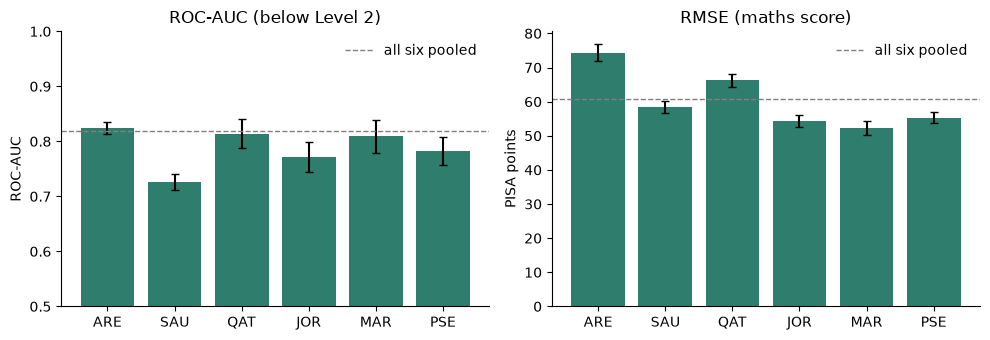

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
pooled = results.set_index("metric")["score"]
titles = {"roc_auc": "ROC-AUC (below Level 2)", "rmse": "RMSE (maths score)"}
for ax, metric in zip(axes, ["roc_auc", "rmse"]):
    d = by_system[by_system["metric"] == metric].set_index("system").loc[SYSTEMS]
    ax.bar(SYSTEMS, d["score"], yerr=1.96 * d["se"], color="#2F7D6D", capsize=3)
    ax.axhline(pooled[metric], color="grey", ls="--", lw=1, label="all six pooled")
    ax.set_title(titles[metric])
    ax.legend(frameon=False)
axes[0].set_ylim(0.5, 1)
axes[0].set_ylabel("ROC-AUC")
axes[1].set_ylabel("PISA points")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_hgb_by_system.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** bars are the per-system scores with 95% intervals (1.96 se), and the dashed line is the pooled score from section 5. The per-system se behind the error bars are in `outputs/ahmed_hgb_by_system.csv`. They are larger than the pooled ones (0.006 to 0.015 for ROC-AUC, 0.8 to 1.2 points for RMSE), so only the bigger gaps between systems are clear. ARE (0.824), QAT (0.814) and MAR (0.809) are within the noise of the pooled ROC-AUC of 0.819, while PSE (0.783), JOR (0.771) and SAU (0.726) are clearly lower.

To read the per-system R² and RMSE we also need the spread of the maths score inside each system (PV1, weighted the same way).

In [11]:
sd = {cnt: np.sqrt(np.cov(d["PV1MATH"], aweights=d["W_FSTUWT"])) for cnt, d in df.groupby("CNT")}
sd["pooled"] = np.sqrt(np.cov(df["PV1MATH"], aweights=df["SENWT"]))
pd.Series(sd)[SYSTEMS + ["pooled"]].round(1).rename("sd_PV1MATH")

ARE       102.0
SAU        64.9
QAT        88.3
JOR        62.3
MAR        63.1
PSE        66.3
pooled     80.7
Name: sd_PV1MATH, dtype: float64

> **Note:** RMSE follows the spread of the scores. ARE (74.4) and QAT (66.3) have the widest spread (SD 102 and 88 against 81 pooled) and the largest errors, but also the highest R² (0.460 and 0.429). The other four have an SD of 62 to 66, RMSE of 52 to 59 and R² of only 0.20 to 0.30. The two recalls in the table at the start of this section also differ a lot between systems. In MAR, PSE and JOR the model catches 0.88 or more of the students below Level 2 but correctly leaves out only 0.37 to 0.48 of those above it, so at the 0.5 threshold it flags most students there. In ARE it is the other way round: it catches only 0.59 of the students below Level 2 and correctly leaves out 0.86 of those above. So one threshold for all six systems is lopsided inside most of them, which we follow up in `ahmed_country_immigrant.ipynb`.

# 7) Looking inside the model
Sections 3 to 6 give the scores. Here we look at what is behind them: where the model goes wrong (7.1), whether more data would help (7.2), which cut-off to use for the flag (7.3), which predictors it relies on (7.4) and what shape the links of the top three have (7.5). Apart from the learning curve, everything reuses the test predictions and the models from sections 3 and 4.

# 7.1) Confusion matrix and curves
One ROC-AUC number hides where the mistakes are. We stitch the five test folds together so every student has one prediction and draw three pictures. They use PV1 only; the other PVs look the same, and their scores are in section 3. The confusion matrix is at the 0.5 cut-off and shows each true class as shares that add up to 1 along a row. All three use the `SENWT` weights.

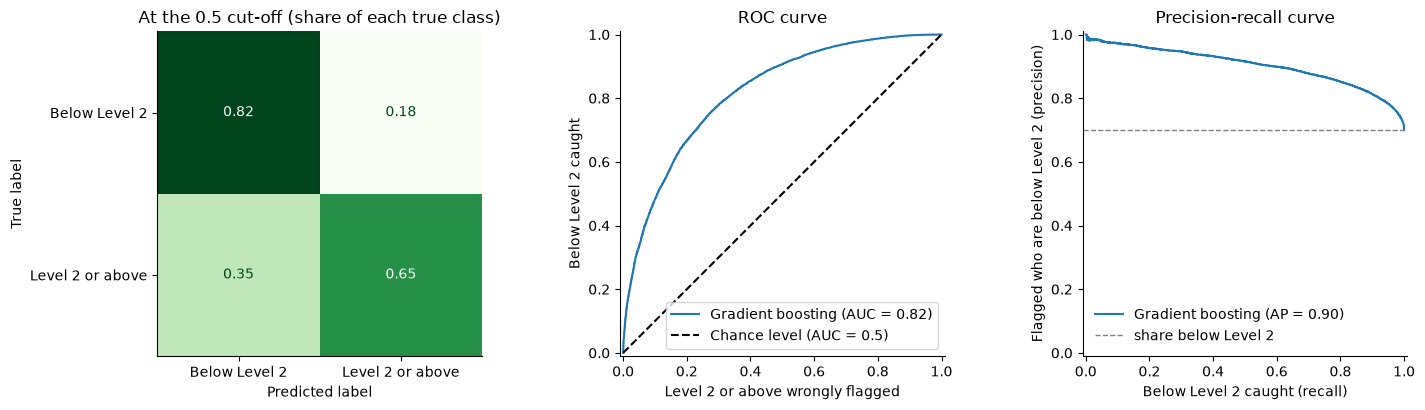

In [12]:
y1, p1 = target("classification", 1), clf_preds[1]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay.from_predictions(y1, (p1 > 0.5).astype(int), labels=[1, 0], sample_weight=w, normalize="true",
                                        display_labels=["Below Level 2", "Level 2 or above"],
                                        cmap="Greens", colorbar=False, ax=axes[0])
RocCurveDisplay.from_predictions(y1, p1, sample_weight=w, name="Gradient boosting", plot_chance_level=True, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y1, p1, sample_weight=w, name="Gradient boosting", ax=axes[2])
# the built-in chance line ignores the weights, so we draw the weighted share ourselves
axes[2].axhline(np.average(y1, weights=w), color="grey", ls="--", lw=1, label="share below Level 2")
axes[0].set_title("At the 0.5 cut-off (share of each true class)")
axes[1].set(title="ROC curve", xlabel="Level 2 or above wrongly flagged", ylabel="Below Level 2 caught")
axes[2].set(title="Precision-recall curve", xlabel="Below Level 2 caught (recall)",
            ylabel="Flagged who are below Level 2 (precision)")
axes[2].legend(loc="lower left", frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "ahmed_hgb_curves.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** on PV1 the model catches 0.82 of the students below Level 2 and wrongly flags 0.35 of those at Level 2 or above (it correctly leaves out 0.65 of them), the same picture as the two recalls in section 3. The ROC curve climbs steeply at the start, because the students with the highest predicted risk are nearly all below Level 2. For the same reason precision stays above 0.9 until more than half of the students below Level 2 are caught. The AUC (0.82) and AP (0.90) in the legends are over the five folds stitched together, so they can differ a little from the fold means in section 3. The dashed line on the right is the share below Level 2 (0.70), where a model that guessed would sit.

# 7.2) Learning curve: does more data help?
If the test score is still going up when the model sees all the training data, more students would help. If it has flattened, the limit is what the 17 predictors carry. In each fold we keep 10%, 25%, 50% and 100% of the training schools (whole schools picked at random with `random_state=0`, so the test fold is still made of unseen schools, and each smaller share sits inside the bigger one). We refit the PV1 winner for both tasks and score it on the full test fold and on the training rows it used.

In [13]:
SHARES = [0.1, 0.25, 0.5, 1.0]
rows = []
for task, metric in [("classification", "roc_auc"), ("regression", "rmse")]:
    y = target(task, 1)
    for k in range(5):
        test = df["fold"] == k
        schools = df.loc[~test, "CNTSCHID"].drop_duplicates().sample(frac=1, random_state=0)
        for share in SHARES:
            used = ~test & df["CNTSCHID"].isin(schools.iloc[:round(share * len(schools))])
            model = fit(task, best[task], used, y)
            rows.append({"task": task, "share": share, "fold": k, "students": used.sum(),
                         "train": score(task, y[used], predict(task, model, used), w[used])[metric],
                         "test": score(task, y[test], predict(task, model, test), w[test])[metric]})
curve = pd.DataFrame(rows).groupby(["task", "share"])[["students", "train", "test"]].mean()
curve.round(4)

students    train     test
task           share                            
classification 0.10     4886.2   0.9684   0.8028
               0.25    12296.4   0.9151   0.8087
               0.50    24557.8   0.8853   0.8140
               1.00    49420.0   0.8578   0.8179
regression     0.10     4886.2  37.2816  63.9701
               0.25    12296.4  47.2099  62.2955
               0.50    24557.8  51.6821  61.4543
               1.00    49420.0  55.1937  60.9491

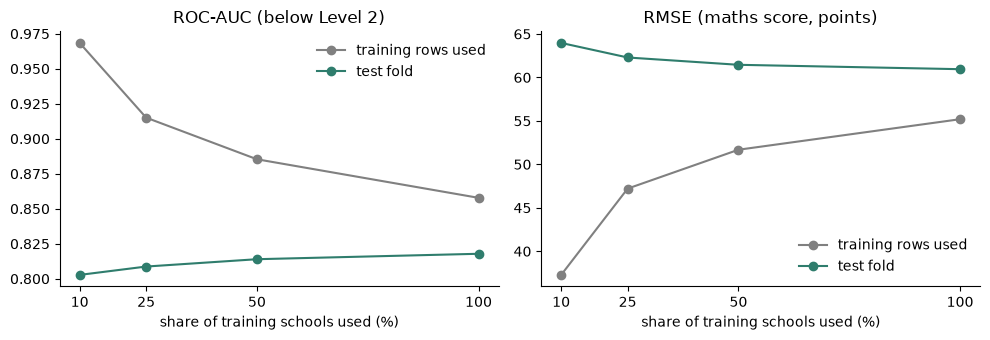

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
titles = {"classification": "ROC-AUC (below Level 2)", "regression": "RMSE (maths score, points)"}
for ax, task in zip(axes, ["classification", "regression"]):
    d = curve.loc[task]
    ax.plot(d.index * 100, d["train"], marker="o", color="grey", label="training rows used")
    ax.plot(d.index * 100, d["test"], marker="o", color="#2F7D6D", label="test fold")
    ax.set_xticks([10, 25, 50, 100])
    ax.set(title=titles[task], xlabel="share of training schools used (%)")
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "ahmed_hgb_learning_curve.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** from 10% to 100% of the training schools the ROC-AUC goes 0.803, 0.809, 0.814 and 0.818, and the RMSE drops by 1.7, 0.8 and 0.5 points. The whole climb is clear (0.015 ROC-AUC and 3.0 points, about 4 and 9 se of the pooled scores in sections 3 and 4). Each single step is small, though: the last doubling adds 0.004 ROC-AUC and takes 0.5 points off the RMSE, about one and 1.5 se, so it is within the noise. The ROC-AUC steps shrink only slowly (0.006, 0.005 and 0.004), and the right end of the plot looks flatter than it is because the x axis is not on a log scale. The training score comes down towards the test score as the data grows (ROC-AUC 0.858 against 0.818 and RMSE 55.2 against 60.9 points at 100%), so with more data the model overfits less. More students of the same kind would add little. The limit is mainly what the 17 predictors carry. The 100% point is the same model as the winner in section 2 (0.8179 and 60.95).

# 7.3) Choosing the cut-off
0.5 is only the default. A school may prefer to catch more of the students below Level 2 and accept flagging more who are fine, or the other way round. With the test predictions of all 10 PVs we try cut-offs from 0.3 to 0.7 and give the share of students flagged, recall for both classes, balanced accuracy and precision (the share of flagged students who really are below Level 2).

Then the "top of the risk list" view from Allali and Zouiri (2026): if a school can only support the 10%, 20% or 30% of students with the highest predicted risk, how many of them are really below Level 2 (precision), and what share of all students below Level 2 does that catch (recall below)? We rank the students of each test fold by predicted risk and take the top share by `SENWT` weight. Everything is combined over PVs and folds with `rubin`.

In [15]:
def flag_scores(y, flag, sw):
    return {"flagged": np.average(flag, weights=sw),
            "precision": precision_score(y, flag, sample_weight=sw),
            "recall_below": recall_score(y, flag, pos_label=1, sample_weight=sw),
            "recall_above": recall_score(y, flag, pos_label=0, sample_weight=sw),
            "balanced_acc": balanced_accuracy_score(y, flag, sample_weight=sw)}


def top(p, sw, share):
    # flag the given share of students (by weight) with the highest predicted risk
    ranked = p.sort_values(ascending=False).index
    return (sw.loc[ranked].cumsum() <= share * sw.sum()).reindex(p.index)


rows = []
for pv in PVS:
    y = target("classification", pv)
    for k in range(5):
        test = df["fold"] == k
        p, sw = clf_preds[pv][test], w[test]
        for cut in [0.3, 0.4, 0.5, 0.6, 0.7]:
            rows.append({"rule": "cut-off", "value": cut, "pv": pv, "fold": k, **flag_scores(y[test], p > cut, sw)})
        for share in [0.1, 0.2, 0.3]:
            rows.append({"rule": "top share", "value": share, "pv": pv, "fold": k,
                         **flag_scores(y[test], top(p, sw, share), sw)})

cutoffs = []
for (rule, value), d in pd.DataFrame(rows).groupby(["rule", "value"]):
    r = rubin(d.drop(columns=["rule", "value"]))
    cutoffs.append(r.rename_axis("metric").reset_index().assign(rule=rule, value=value))
cutoffs = pd.concat(cutoffs)[["rule", "value", "metric", "score", "se"]]
cutoffs.to_csv(OUT / "ahmed_hgb_cutoffs.csv", index=False)
cutoffs.pivot_table(index=["rule", "value"], columns="metric", values=["score", "se"]).round(3)

score                                              \
metric          balanced_acc flagged precision recall_above recall_below   
rule      value                                                            
cut-off   0.3          0.676   0.837     0.788        0.410        0.943   
          0.4          0.713   0.764     0.817        0.534        0.892   
          0.5          0.735   0.682     0.845        0.647        0.823   
          0.6          0.739   0.589     0.871        0.746        0.732   
          0.7          0.722   0.475     0.897        0.837        0.608   
top share 0.1          0.563   0.100     0.966        0.989        0.138   
          0.2          0.619   0.200     0.950        0.966        0.271   
          0.3          0.665   0.300     0.931        0.931        0.399   

                          se                                              
metric          balanced_acc flagged precision recall_above recall_below  
rule      value                                                           
cut-off   0.3          0.004   0.004     0.003        0.008        0.002  
          0.4          0.004   0.005     0.003        0.009        0.003  
          0.5          0.004   0.006     0.003        0.009        0.004  
          0.6          0.003   0.006     0.003        0.008        0.004  
          0.7          0.003   0.005     0.003        0.006        0.005  
top share 0.1          0.001   0.000     0.004        0.001        0.001  
          0.2          0.002   0.000     0.004        0.002        0.002  
          0.3          0.002   0.000     0.003        0.003        0.002

> **Note:** the 0.5 row is the same as section 3. Moving the cut-off trades one recall for the other: a lower cut-off flags more students and catches more of those below Level 2, but correctly leaves out fewer of those above. Balanced accuracy is highest at a cut-off of 0.6 (0.739, se 0.003, against 0.735, se 0.004, at 0.5), but that gap is within the noise. So the cut-off is a choice about which mistake a school can live with more than a way to make the model better, and one pooled cut-off can't fix the lopsided flag inside systems from section 6. The top of the risk list is precise: 0.966 of the 10% with the highest risk are really below Level 2, and 0.931 of the top 30%. But since about 70% of students are below Level 2 (section 1), even the top 30% can catch at most 0.3 / 0.7 = 43% of them, and it catches 40% (0.399). In these six systems a short risk list finds students who clearly need help, but it reaches only a small part of them.

# 7.4) Which predictors matter
A model we can't explain is hard to use in a report. Permutation importance shuffles one predictor at a time in the test fold and measures how much the score drops: ROC-AUC for below Level 2, and RMSE for the maths score (there the drop is the rise in error, in points). It uses the stored models from sections 3 and 4, the test rows of each fold weighted with `SENWT`, and 5 shuffles per predictor, on all 10 PVs. Each predictor's drop is then combined over PVs and folds with `rubin`.

One thing to keep in mind: when two predictors carry the same information (the four family ones, or the two self-efficacy scales), shuffling one leaves the other to stand in for it, so each looks less important than the pair is. The ablations notebook drops whole groups for that reason.

In [16]:
SCORING = {"classification": "roc_auc", "regression": "neg_root_mean_squared_error"}
rows = []
for task, models in [("classification", clf_models), ("regression", reg_models)]:
    for pv in PVS:
        y = target(task, pv)
        for k in range(5):
            test = df["fold"] == k
            imp = permutation_importance(models[(pv, k)], X[test], y[test], scoring=SCORING[task],
                                         n_repeats=5, random_state=0, sample_weight=w[test])
            rows.append({"task": task, "pv": pv, "fold": k, **dict(zip(FEATURES, imp.importances_mean))})
imp_folds = pd.DataFrame(rows)

importance = []
for task, d in imp_folds.groupby("task"):
    r = rubin(d.drop(columns="task"))
    importance.append(r.rename_axis("predictor").reset_index().assign(task=task))
importance = pd.concat(importance).rename(columns={"score": "drop"})[["task", "predictor", "drop", "se"]]
importance.to_csv(OUT / "ahmed_hgb_importance.csv", index=False)
importance.pivot(index="predictor", columns="task", values=["drop", "se"]).sort_values(("drop", "regression"), ascending=False).round(4)

drop                        se           
task         classification regression classification regression
predictor                                                       
MATHEFF              0.0308     5.3915         0.0023     0.2518
SCHL_PRIVATE         0.0268     5.0554         0.0026     0.3677
BULLIED              0.0184     2.3121         0.0019     0.1708
HISEI                0.0109     1.6181         0.0015     0.0828
SCHSIZE_log          0.0057     1.6016         0.0013     0.2093
ESCS                 0.0072     1.1114         0.0013     0.1791
HOMEPOS              0.0112     1.1084         0.0014     0.1069
ANXMAT               0.0062     0.9882         0.0009     0.0998
DISCLIM              0.0065     0.9578         0.0010     0.0696
BELONG               0.0028     0.5209         0.0007     0.0654
STRATIO              0.0036     0.5168         0.0009     0.0885
TEACHSUP             0.0020     0.5074         0.0003     0.0629
MATHEF21             0.0015     0.3748         0.0004     0.0555
MCLSIZE              0.0016     0.1933         0.0004     0.0507
STAFFSHORT           0.0004     0.1639         0.0003     0.0386
EDUSHORT             0.0004     0.1495         0.0003     0.0481
PAREDINT             0.0002     0.1098         0.0001     0.0296

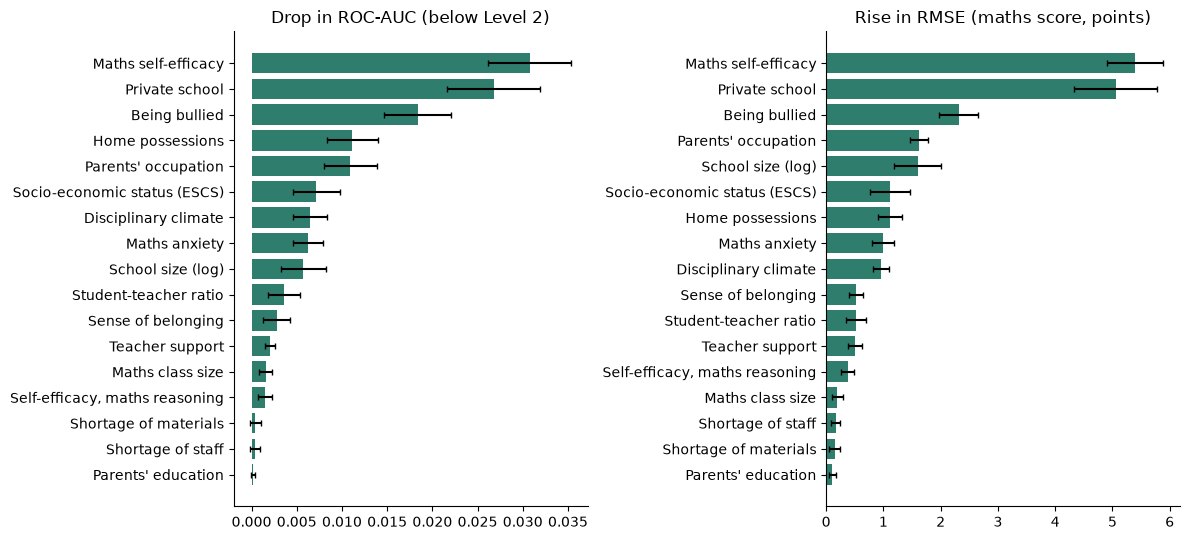

In [17]:
NAMES = {"ESCS": "Socio-economic status (ESCS)", "PAREDINT": "Parents' education", "HISEI": "Parents' occupation",
         "HOMEPOS": "Home possessions", "ANXMAT": "Maths anxiety", "MATHEFF": "Maths self-efficacy",
         "MATHEF21": "Self-efficacy, maths reasoning", "DISCLIM": "Disciplinary climate", "TEACHSUP": "Teacher support",
         "BELONG": "Sense of belonging", "BULLIED": "Being bullied", "EDUSHORT": "Shortage of materials",
         "STAFFSHORT": "Shortage of staff", "MCLSIZE": "Maths class size", "STRATIO": "Student-teacher ratio",
         "SCHL_PRIVATE": "Private school", "SCHSIZE_log": "School size (log)"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
titles = {"classification": "Drop in ROC-AUC (below Level 2)", "regression": "Rise in RMSE (maths score, points)"}
for ax, task in zip(axes, ["classification", "regression"]):
    d = importance[importance["task"] == task].sort_values("drop")
    ax.barh([NAMES[c] for c in d["predictor"]], d["drop"], xerr=1.96 * d["se"], color="#2F7D6D", capsize=2)
    ax.set_title(titles[task])
fig.tight_layout()
fig.savefig(FIGS / "ahmed_hgb_importance.png", bbox_inches="tight", dpi=150)
plt.show()

If the order of the predictors changed a lot from one PV to the next, we couldn't say much about it. So we rank the predictors on each PV (mean drop over the 5 folds) and compare every pair of PVs with Kendall's tau, where 1 means the same order.

In [18]:
taus = []
for task, d in imp_folds.groupby("task"):
    per_pv = d.drop(columns=["task", "fold"]).groupby("pv").mean()
    t = pd.Series([kendalltau(per_pv.loc[a], per_pv.loc[b]).statistic for a, b in combinations(PVS, 2)], dtype=float)
    taus.append({"task": task, "pairs": len(t), "mean_tau": t.mean(), "min_tau": t.min()})
pd.DataFrame(taus).round(3)

,task,pairs,mean_tau,min_tau
0,classification,45,0.914,0.853
1,regression,45,0.922,0.868


Private school ranks high, so we check how common private schools are in each system and how far apart private and public students score before the model adjusts for anything (weighted, mean over the PVs).

In [19]:
rows = {}
for cnt, d in [("all six", df)] + list(df.groupby("CNT")):
    sw = d["SENWT"] if cnt == "all six" else d["W_FSTUWT"]
    ok = d["SCHL_PRIVATE"].notna()
    private, public = ok & (d["SCHL_PRIVATE"] == 1), ok & (d["SCHL_PRIVATE"] == 0)
    gap = np.mean([np.average(d.loc[private, f"PV{pv}MATH"], weights=sw[private])
                   - np.average(d.loc[public, f"PV{pv}MATH"], weights=sw[public]) for pv in PVS])
    rows[cnt] = {"private_share": np.average(d.loc[ok, "SCHL_PRIVATE"], weights=sw[ok]), "private_minus_public": gap}
pd.DataFrame(rows).T.loc[["all six"] + SYSTEMS].round(2)

,private_share,private_minus_public
all six,0.26,75.08
ARE,0.60,94.50
SAU,0.17,25.71
QAT,0.47,75.69
JOR,0.20,38.06
MAR,0.10,55.56
PSE,0.06,67.10


> **Note:** maths self-efficacy and private school are the top two for both tasks, and they are within the noise of each other (ROC-AUC drops of 0.031 and 0.027 with se 0.002 and 0.003, RMSE rises of 5.39 and 5.06 points with se 0.25 and 0.37), so neither is clearly first. Being bullied is third (a drop of 0.018 and a rise of 2.31 points). Both of the top two are clearly ahead of it, even private school for below Level 2 (0.027 against 0.018, a gap of more than 2 se). The order barely changes between PVs: Kendall's tau is 0.914 on average and 0.853 at the lowest for below Level 2, and 0.922 and 0.868 for the maths score. Self-efficacy in the top two matches Huang et al. (2024) and Eren and Niksarli (2026). Their other top predictor, home resources, comes lower here (home possessions drops ROC-AUC by 0.011), partly because ESCS is built from the other three family predictors, so they stand in for each other when one is shuffled. Private school probably ranks high partly because it also marks the systems with large private sectors: 0.60 of students in the UAE and 0.47 in Qatar are in private schools, against 0.06 to 0.20 in the other four, and private school students score 75 points more than public ones over all six before anything else is taken into account (94 in the UAE).

# 7.5) Shape of the top three predictors
The importance above says how much a predictor matters, not how, and the EDA found several links that are not straight lines. A partial dependence plot sets one predictor to the same value for every student, averages the predicted maths score, and repeats this across the predictor's range, so the curve shows what the model learned for that predictor with the others left as they are. We use the PV1 regression model of fold 0 on its test fold (weighted with `SENWT`) and the three predictors with the largest RMSE rise in 7.4.

scikit-learn builds its grid of values and its decile ticks with the blanks counted in, which leaves the curve empty for a predictor with many blanks. So we give it the grid ourselves (every 5th percentile from the 5th to the 95th, among the students who answered; the dictionary has to use column numbers, names are ignored) and take the decile ticks off.

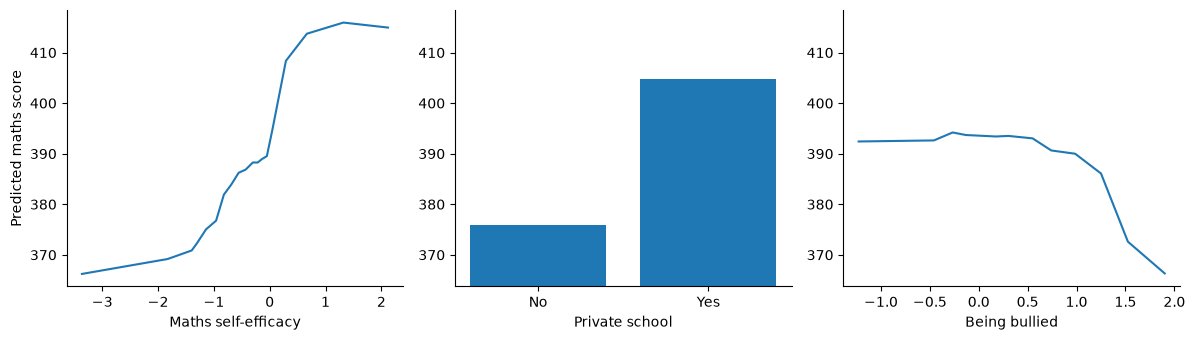

MATHEFF         48.7
SCHL_PRIVATE    28.9
BULLIED        -26.1
Name: change, dtype: float64

In [20]:
top3 = importance[importance["task"] == "regression"].nlargest(3, "drop")["predictor"].tolist()
test0 = df["fold"] == 0
binary = [c for c in top3 if X[c].dropna().nunique() == 2]
grid = {FEATURES.index(c): np.array([0.0, 1.0]) if c in binary else np.unique(X[c].quantile(np.linspace(0.05, 0.95, 19)))
        for c in top3}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
disp = PartialDependenceDisplay.from_estimator(reg_models[(1, 0)], X[test0], top3, sample_weight=w[test0],
                                               custom_values=grid, categorical_features=[FEATURES.index(c) for c in binary],
                                               ax=axes)
for ax, ticks, c in zip(axes, disp.deciles_vlines_, top3):
    if ticks is not None:
        ticks.remove()
    if c in binary:
        ax.set_xticks([0, 1], ["No", "Yes"], rotation=0)
    ax.relim()
    ax.autoscale_view()
    ax.set(xlabel=NAMES[c], ylabel="")
axes[0].set_ylabel("Predicted maths score")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_hgb_partial_dependence.png", bbox_inches="tight", dpi=150)
plt.show()

# predicted score at the 95th percentile minus at the 5th
pd.Series({c: r["average"][0][-1] - r["average"][0][0] for c, r in zip(top3, disp.pd_results)}).round(1).rename("change")

> **Note:** none of the three is a straight line. Maths self-efficacy is S-shaped: the curve is nearly flat for the least confident students (below about -1.5), climbs steeply between about -1.5 and 0.7, and is flat again above that, so the model sees little difference among students who are very unsure of themselves, or among very confident ones. From the 5th to the 95th percentile it is worth 48.7 points. Private school only takes two values, so it is drawn as two bars: a step of 28.9 points. That is well under the raw gap of 75 points in 7.4, because the model also sees the family background and the system that go with private schools. Being bullied makes almost no difference up to about 1 on its scale and then lowers the predicted score fast, by 26.1 points at the 95th percentile, so only frequent bullying shows up. This fits the EDA, which found several links that are not straight lines, and a linear model would miss the bends in self-efficacy and bullying.

# 8) Summary

On the 17 predictors, gradient boosting reaches ROC-AUC 0.819 (se 0.004) for below Level 2 and RMSE 60.75 points (R² 0.428) for the maths score, and more data of the same kind would add little.

- Tuning on PV1 picked a learning rate of 0.05 with 31 leaves for classification and 63 for regression (`outputs/ahmed_hgb_params.json`). The 100-tree cap is enough: with 1000 allowed the score stays the same (ROC-AUC 0.8179 and 0.8178, RMSE 60.95 and 60.93).
- Going from half to all of the training schools adds only 0.004 ROC-AUC and takes only 0.5 points off the RMSE, within the noise. The limit is mainly what the 17 predictors carry.
- Per system, ROC-AUC goes from 0.726 (SAU) to 0.824 (ARE), and PSE, JOR and SAU are clearly below the pooled score. At the 0.5 cut-off the flag is lopsided: it flags most students in MAR, PSE and JOR, but in ARE it catches only 0.59 of those below Level 2 (`outputs/ahmed_hgb_by_system.csv`).
- The cut-off trades one recall for the other, and no cut-off from 0.3 to 0.7 is clearly better than 0.5 on balanced accuracy. The 10% with the highest predicted risk are almost all below Level 2 (precision 0.966), but they are only 0.138 of all students below Level 2 (`outputs/ahmed_hgb_cutoffs.csv`).
- Maths self-efficacy and private school are the top two for both tasks, within the noise of each other, then being bullied. The order barely changes across PVs (mean Kendall's tau 0.914 and 0.922). Self-efficacy has an S shape, private school is a step of 28.9 points and bullying only lowers the score at high values (`outputs/ahmed_hgb_importance.csv`).

For the report: the pooled scores in `outputs/ahmed_hgb_results.csv` for the model table, `ahmed_hgb_by_system.png` with the point that the 0.5 flag is lopsided inside most systems, `ahmed_hgb_curves.png`, `ahmed_hgb_importance.png` with the top two (figures in `outputs/figures/`), and the cut-off table and top-10% numbers from `outputs/ahmed_hgb_cutoffs.csv` for the recommendations.

Next: `ahmed_ablations.ipynb` (drop each factor group in turn), `../04_neural-networks/ahmed_mlp.ipynb` (MLP compared with this model), `ahmed_country_immigrant.ipynb` (whether to add country or immigrant status, and a flag balanced inside each system) and `ahmed_trials.ipynb` (other things we tried).